# Import the relevant databases and related functions

In [1]:
# General
import pandas as pd
import numpy as np
import pathlib
import matplotlib.pyplot as plt
%matplotlib inline

# ML
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
import joblib
from xgboost import XGBRegressor 

# Cp 
from cp_app.utils import select_structures_new
from cp_app.descriptors import new4plmf_plusc_plus_newc_400D,new_new4_plmf,new_simple_c_2,new_c_plus_new_plmf,new_PLMF_C_100D,new_PLMF_C_200D,new_PLMF_C_300D,new_PLMF_C_400D,new_PLMF_C_450D,new_PLMF_C_500D,new_561D_PLMF,simple_descriptors,diff_and_pure, PLMF_477D, PLMF_first_400D, PLMF_first_300D, PLMF_first_200D, PLMF_first_100D, PLMF_first_20D, C_PLUS_PLMF_400D, C_PLUS_PLMF_300D, C_PLUS_PLMF_200D, C_PLUS_PLMF_100D, C_PLUS_PLMF_20D, MP, LEAF,mp1_C_PLMF_100D,mp1_C_PLMF_200D,mean_plus_diff,C_PLUS_PLMF_PLUS_DIFF_100D
from cp_app.predictions import predict_G_ensemble_dataset

# others
import warnings
warnings.filterwarnings('ignore')
import shap
import seaborn as sns
from hyperopt import hp, fmin, tpe, Trials, STATUS_OK
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Load the training dataset

In [24]:
RANDOM_SEED = 3982
DATA_DIR = 'D:/code&data availability/Datasets/training and test datasets/540 samples (from MP;after checking)/new_plmf+c/'#C+PLMF_xxD&MP/'
DATA_ALL = 'alldata.csv'
flag="smallML_432_10" # name_#TrainSize_#EnsembleSize
N_ensemble = int(flag.split("_")[2])
N_train=int(flag.split("_")[1])
df_allsites = pd.read_csv(DATA_DIR+DATA_ALL,encoding='gb2312')
print("Total structures: ", len(df_allsites))


Total structures:  540


# Randomly split the dataset

In [25]:
inds=select_structures_new(N_train,df_allsites)
df_train_allsites=df_allsites.loc[df_allsites.index.isin(inds)]
df_test_allsites=df_allsites.loc[~df_allsites.index.isin(inds)]
df_train_allsites.to_csv(DATA_DIR+"training_sets.csv")
df_test_allsites.to_csv(DATA_DIR+"test_sets.csv")
print("{} structures in training set".format(len(df_train_allsites)))
print("{} structures in test set".format(len(df_test_allsites)))

432 structures in training set
108 structures in test set


# Define variables and the model training function

In [26]:
FEATURES = new_PLMF_C_200D#C_PLUS_PLMF_100D+['Formation Energy per Atom (eV/atom)']+['Energy per Atom (eV/atom)']
TARGET = '300'#temperature
def xgb_model(best_params, X, FEATURES, TARGET):
    pipe_xgb = Pipeline(
        [   ('scaling', StandardScaler()),
       ('xgb', XGBRegressor(colsample_bynode= 0.05))
        ]  )
    pipe_xgb.set_params(xgb__reg_lambda = best_params["xgb__reg_lambda"])#:L2 regularize 
    pipe_xgb.set_params(xgb__reg_alpha = best_params["xgb__reg_alpha"])#:L1 regularize 
    pipe_xgb.set_params(xgb__n_estimators = best_params["xgb__n_estimators"])
    pipe_xgb.set_params(xgb__max_depth = best_params["xgb__max_depth"])
    pipe_xgb.set_params(xgb__learning_rate = best_params["xgb__learning_rate"])
    pipe_xgb.fit(X[FEATURES], X[TARGET])
    return pipe_xgb

# Optimize hyperparameters using five-fold cross-validation

In [27]:
def objective(params):
    pipe_xgb = Pipeline([
        ('scaling', StandardScaler()),
        ('xgb', XGBRegressor(random_state=RANDOM_SEED))
    ])
    
    pipe_xgb.set_params(
        xgb__reg_lambda=params['reg_lambda'],
        xgb__reg_alpha=params['reg_alpha'],
        xgb__n_estimators=int(params['n_estimators']),
        xgb__max_depth=int(params['max_depth']),
        xgb__learning_rate=params['learning_rate']
        
    )
    X=df_train_allsites
    score = cross_val_score(pipe_xgb, X[FEATURES], X[TARGET], cv=5, scoring='r2').mean()
    return {'loss': -score, 'status': STATUS_OK}

space = {
    'reg_lambda': hp.loguniform('reg_lambda', np.log(1e-2), np.log(10)),
    'reg_alpha': hp.loguniform('reg_alpha', np.log(1e-2), np.log(10)),
    'n_estimators': hp.quniform('n_estimators', 50, 500, 10),
    'max_depth': hp.quniform('max_depth', 3, 10, 1),
    'learning_rate': hp.loguniform('learning_rate', np.log(1e-3), np.log(0.3))
    
}

trials = Trials()
best = fmin(
    fn=objective,
    space=space,
    algo=tpe.suggest,
    max_evals=25,
    trials=trials,
    rstate=np.random.default_rng(RANDOM_SEED)
)

xgb_hyperparams = {
    'xgb__reg_lambda': best['reg_lambda'],
    'xgb__reg_alpha': best['reg_alpha'],
    'xgb__n_estimators': int(best['n_estimators']),
    'xgb__max_depth': int(best['max_depth']),
    'xgb__learning_rate': best['learning_rate']
    
}

print("best hyperparameters:", xgb_hyperparams)

100%|█████████████████████████████████████████████████████| 25/25 [04:30<00:00, 10.81s/trial, best loss: -0.7773912480143743]
best hyperparameters: {'xgb__reg_lambda': 5.146666314141774, 'xgb__reg_alpha': 0.7747187848273281, 'xgb__n_estimators': 230, 'xgb__max_depth': 3, 'xgb__learning_rate': 0.1652617556225032}


# Generate multiple training subsets by resampling

In [28]:
Xs = []
for i in range(N_ensemble):
    X = resample(df_train_allsites, replace=True,random_state=i)
    Xs.append(X)

# Train and save the model

In [29]:
models = []
for i,X in enumerate(Xs):
    model = xgb_model(xgb_hyperparams, X, FEATURES, TARGET)
    models.append(model)
p = pathlib.Path("ensemble_models_{}/{}".format(flag,TARGET))
p.mkdir(parents=True, exist_ok=True)
for i,model in enumerate(models):
    joblib.dump(model,"ensemble_models_{}/{}/model_{}".format(flag,TARGET,i))

# Predict on the training set and evaluate performance

Training Set MAE: 2892.5091
Training Set RMSE: 4192.9698
Training Set R²: 0.9724


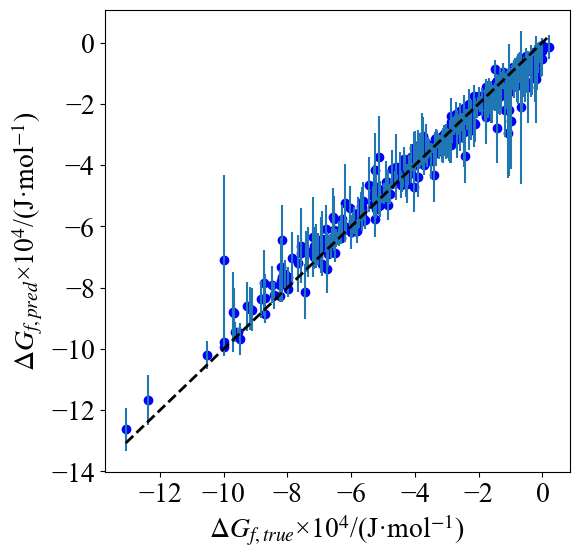

In [30]:
import matplotlib.ticker as ticker
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'stix'  

predictions = []
for model in models:
    prediction = model.predict(df_train_allsites[FEATURES])
    predictions.append(prediction)

predictions = np.array(predictions)
pred_mean = np.mean(predictions, axis=0)
pred_std = np.std(predictions, axis=0)
y_true = df_train_allsites[TARGET]
mae = mean_absolute_error(y_true, pred_mean)
rmse = np.sqrt(mean_squared_error(y_true, pred_mean))
r2 = r2_score(y_true, pred_mean)

df_results = pd.DataFrame({
    'Formula': df_train_allsites['Formula'],
    'MP_ID': df_train_allsites['MP_ID'],
    'pred_mean': pred_mean,
    'pred_std': pred_std
})
#df_results.to_csv('C+PLMF_100D&EE_predictions_results_for_training_sets.csv', index=False)
#print("Predictions saved to 'predictions_results.csv'")

print(f"Training Set MAE: {mae:.4f}")
print(f"Training Set RMSE: {rmse:.4f}")
print(f"Training Set R²: {r2:.4f}")

plt.figure(figsize=(6, 6))

plt.errorbar(y_true, pred_mean, yerr=pred_std, linestyle="None", label="Predictions with std")
plt.scatter(y_true, pred_mean, color='blue', label="Mean Predictions")
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'k--', lw=2, label="Ideal")
#plt.xlabel("$\Delta$$H_{f,true}$/(eV·atom$^{-1}$)", fontfamily='Times New Roman', fontsize=20)
#plt.ylabel("$\Delta$$H_{f,pred}$/(eV·atom$^{-1}$)", fontfamily='Times New Roman', fontsize=20)
plt.xlabel("$\Delta$$G_{f,true}$×10$^{4}$/(J·mol$^{-1}$)", fontfamily='Times New Roman', fontsize=20)
plt.ylabel("$\Delta$$G_{f,pred}$×10$^{4}$/(J·mol$^{-1}$)", fontfamily='Times New Roman', fontsize=20)

#plt.title("True vs Predicted Values (Training Set)", fontsize=20)
#plt.legend(prop={'family': 'Times New Roman', 'size': 18})
plt.xticks(fontsize=20, fontfamily='Times New Roman')
plt.yticks(fontsize=20, fontfamily='Times New Roman')
ax = plt.gca()
formatter = ticker.ScalarFormatter(useMathText=True)
formatter.set_powerlimits((-2, 2))
ax.xaxis.set_major_formatter(formatter)
ax.yaxis.set_major_formatter(formatter)
ax.ticklabel_format(style='sci', axis='both', scilimits=(4, 4))
ax.xaxis.offsetText.set_fontsize(20)
ax.yaxis.offsetText.set_fontsize(20)
ax.xaxis.offsetText.set_fontfamily('Times New Roman')
ax.yaxis.offsetText.set_fontfamily('Times New Roman')
ax.get_xaxis().get_offset_text().set_visible(False)
ax.get_yaxis().get_offset_text().set_visible(False)

plt.grid(False)
plt.show()

# Predict on the test set and evaluate performance

MAE: 6213.4908
RMSE: 8701.8296
R²: 0.8800


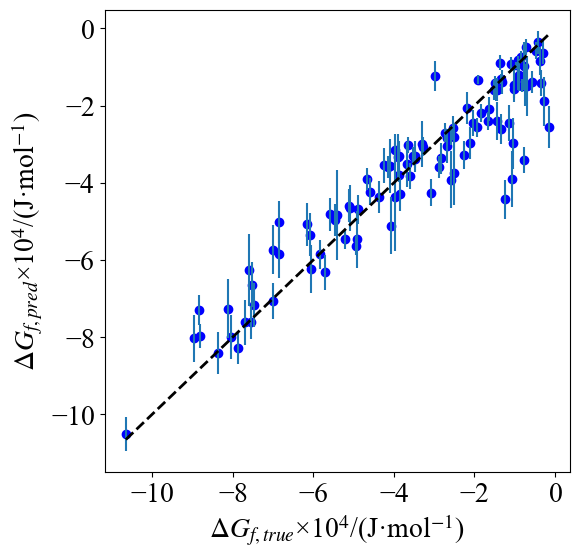

In [31]:
predictions_new = []
for model in models:
    prediction = model.predict(df_test_allsites[FEATURES])
    predictions_new.append(prediction)

predictions_new = np.array(predictions_new)
pred_mean = np.mean(predictions_new, axis=0)
pred_std = np.std(predictions_new, axis=0)
y_true = df_test_allsites[TARGET]

mae = mean_absolute_error(y_true, pred_mean)
rmse = np.sqrt(mean_squared_error(y_true, pred_mean))
r2 = r2_score(y_true, pred_mean)

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")

df_results = pd.DataFrame({
    'Formula': df_test_allsites['Formula'],
    'MP_ID': df_test_allsites['MP_ID'],
    'truth':y_true,
    'pred_mean': pred_mean,
    'pred_std': pred_std
})
#df_results.to_csv('C+PLMF_100D&EE_predictions_results_for_test_sets.csv', index=False)
#print("Predictions saved to 'predictions_results.csv'")

plt.figure(figsize=(6, 6))
plt.errorbar(y_true, pred_mean, yerr=pred_std, linestyle="None", label="Predictions with std")
plt.scatter(y_true, pred_mean, color='blue', label="Mean Predictions")
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'k--', lw=2, label="Ideal")
#plt.xlabel("$\Delta$$H_{f,true}$/(eV·atom$^{-1}$)", fontfamily='Times New Roman', fontsize=20)
#plt.ylabel("$\Delta$$H_{f,pred}$/(eV·atom$^{-1}$)", fontfamily='Times New Roman', fontsize=20)
plt.xlabel("$\Delta$$G_{f,true}$×10$^{4}$/(J·mol$^{-1}$)", fontfamily='Times New Roman', fontsize=20)
plt.ylabel("$\Delta$$G_{f,pred}$×10$^{4}$/(J·mol$^{-1}$)", fontfamily='Times New Roman', fontsize=20)
#plt.title("True vs Predicted Values (Test Set)", fontsize=20)
#plt.legend(prop={'family': 'Times New Roman', 'size': 18})
plt.xticks(fontsize=20, fontfamily='Times New Roman')
plt.yticks(fontsize=20, fontfamily='Times New Roman')
ax = plt.gca()
formatter = ticker.ScalarFormatter(useMathText=True)
formatter.set_powerlimits((-2, 2))
ax.xaxis.set_major_formatter(formatter)
ax.yaxis.set_major_formatter(formatter)
ax.ticklabel_format(style='sci', axis='both', scilimits=(4, 4))
ax.xaxis.offsetText.set_fontsize(20)
ax.yaxis.offsetText.set_fontsize(20)
ax.xaxis.offsetText.set_fontfamily('Times New Roman')
ax.yaxis.offsetText.set_fontfamily('Times New Roman')
ax.get_xaxis().get_offset_text().set_visible(False)
ax.get_yaxis().get_offset_text().set_visible(False)
plt.grid(False)
plt.show()

# Compute SHAP (SHapley Additive exPlanations) values for feature dimensionality reduction and importance analysis

Top 10 Most Important Features and Their Average SHAP Values:
------------------------------------------------------------
1. Warren_Cowley_Order: 2272.053223 ± 374.521515
2. path_IP3_max: 1451.916992 ± 634.152954
3. circular_V_molar/C_min: 1267.084717 ± 883.136536
4. circular_Atomic radius_std: 1249.653931 ± 451.702332
5. path_IP2*ΔH_atom_max: 963.600281 ± 639.802979
6. Electronegativity_Diff: 874.027466 ± 241.128510
7. path_χ_pualing_max: 820.935059 ± 670.606140
8. path_V_molar/C_min: 749.614380 ± 317.877472
9. path_length_std: 725.578979 ± 331.710266
10. circular_χ_pualing*Z_eff_std: 700.430542 ± 307.238525
------------------------------------------------------------
Color bar found in figure axes: True
Color bar label set to: Feature value, fontsize: 20
Color bar tick labels: ['Low', 'High'], fontsize: 20


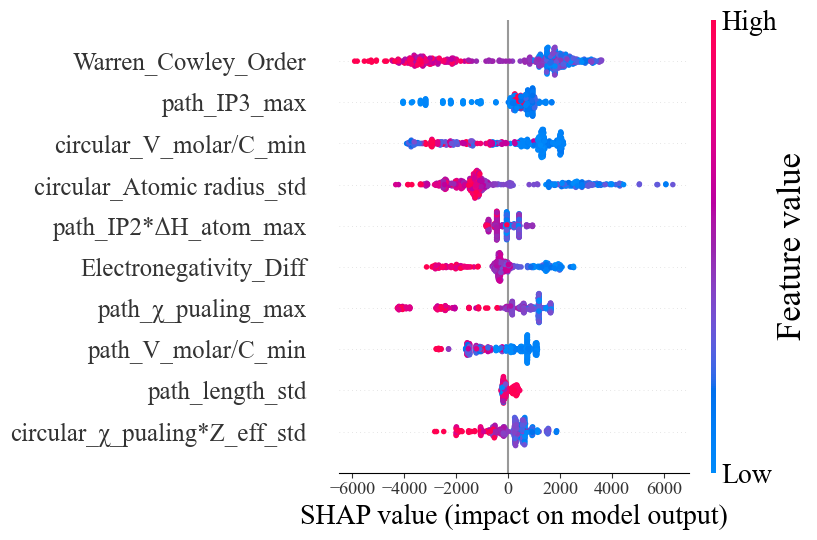

In [34]:
shap_values_list = []
for model in models:
    preprocessor = Pipeline(model.steps[:1])
    X_train_transformed = preprocessor.transform(df_train_allsites[FEATURES])
    xgb_model_test = model.named_steps['xgb']
    explainer = shap.TreeExplainer(xgb_model_test)
    shap_values = explainer.shap_values(X_train_transformed)
    shap_values_list.append(shap_values)

feature_importances = []
for shap_values in shap_values_list:
    importance = np.mean(np.abs(shap_values), axis=0)
    feature_importances.append(importance)

overall_importance = np.mean(feature_importances, axis=0)
importance_std = np.std(feature_importances, axis=0)

top_n = 10
indices = np.argsort(overall_importance)[::-1][:top_n]
print(f"Top {top_n} Most Important Features and Their Average SHAP Values:")
print("-" * 60)
for i, idx in enumerate(indices):
    feature_name = np.array(FEATURES)[idx]
    shap_value = overall_importance[idx]
    shap_std = importance_std[idx]
    print(f"{i+1}. {feature_name}: {shap_value:.6f} ± {shap_std:.6f}")
print("-" * 60)

#shap.summary_plot(shap_values_list[0], df_train_allsites[FEATURES], show=True)
# Get indices of top features (up to the number of features available)
num_features = len(FEATURES)
max_display = min(10, num_features)  # Ensure max_display doesn't exceed number of features
top_indices = np.argsort(overall_importance)[::-1][:max_display]

# Create SHAP Explanation object (using first model's SHAP values)
shap_values = shap_values_list[0]
X_train_transformed = Pipeline(models[0].steps[:1]).transform(df_train_allsites[FEATURES])
explanation = shap.Explanation(
    values=shap_values,
    base_values=explainer.expected_value,
    data=X_train_transformed,
    feature_names=np.array(FEATURES)
)

# Create beeswarm plot
shap.plots.beeswarm(
    explanation,
    max_display=max_display,
    order=np.argsort(overall_importance)[::-1],  # Sort by importance
    group_remaining_features=False,  # Avoid grouping issues
    show=False
)

ax = plt.gca()
# X-axis label (SHAP value)
ax.set_xlabel(ax.get_xlabel(), fontsize=20)
# Y-axis tick labels (feature names)
for label in ax.get_yticklabels():
    label.set_fontsize(18)
# X-axis tick labels
for label in ax.get_xticklabels():
    label.set_fontsize(13)

# Access color bar using Method 2 (figure axes)
cbar = None
fig = plt.gcf()
for cb in fig.get_axes():
    if isinstance(cb, plt.Axes) and cb.get_label().startswith('<colorbar'):
        cbar = cb
        print(f"Color bar found in figure axes: {cbar is not None}")
        break
else:
    print("Warning: Color bar not found in figure axes")

# Apply font size changes to color bar
if cbar is not None:
    try:
        label = 'Feature value'
        cbar.set_ylabel(label, fontsize=25)  # Use set_ylabel for axes object
        # Set color bar tick labels
        cbar.tick_params(axis='y', labelsize=20)
        # Alternative: Directly set font size for all text objects
        for text in cbar.get_yticklabels():
            text.set_fontsize(20)
        # Debugging: Confirm settings
        print(f"Color bar label set to: {cbar.get_ylabel()}, fontsize: 20")
        print(f"Color bar tick labels: {[text.get_text() for text in cbar.get_yticklabels()]}, fontsize: 20")
    except Exception as e:
        print(f"Error modifying color bar: {e}")
else:
    print("Warning: Color bar not found, cannot apply font size changes")
# Adjust layout and display
plt.tight_layout()
plt.show()

## SHAP beeswarm plot

Color bar found in figure axes: True
Color bar label set to: Feature value, fontsize: 20
Color bar tick labels: ['Low', 'High'], fontsize: 20


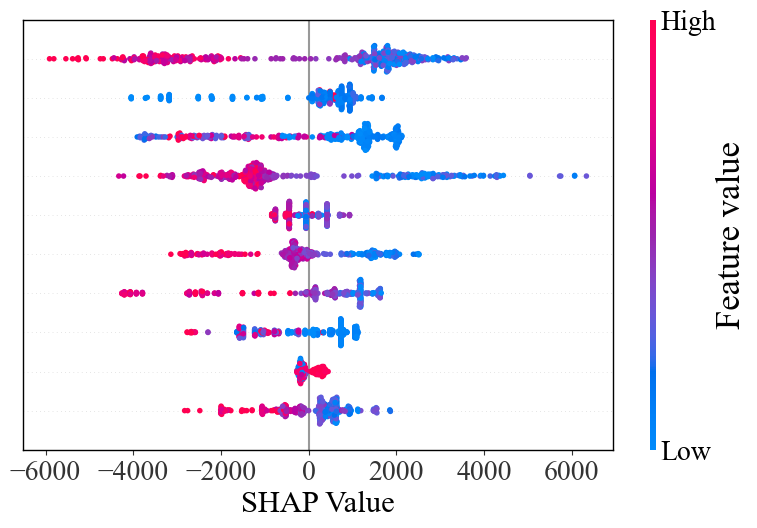

In [35]:
import matplotlib.pyplot as plt
import shap
import numpy as np
from sklearn.pipeline import Pipeline

# Set matplotlib DPI for consistent scaling (optional, adjust as needed)
plt.rcParams['figure.dpi'] = 100  # Higher DPI for larger display, lower for smaller

# Get indices of top features (up to the number of features available)
num_features = len(FEATURES)
max_display = min(10, num_features)  # Ensure max_display doesn't exceed number of features
top_indices = np.argsort(overall_importance)[::-1][:max_display]

# Create SHAP Explanation object (using first model's SHAP values)
shap_values = shap_values_list[0]
X_train_transformed = Pipeline(models[0].steps[:1]).transform(df_train_allsites[FEATURES])
explanation = shap.Explanation(
    values=shap_values,
    base_values=explainer.expected_value,
    data=X_train_transformed,
    feature_names=np.array(FEATURES)
)

# Set figure dimensions (editable, in inches)
figure_width = 12  # Adjust this value to change the width
figure_height = 8  # Adjust this value to change the height

# Create figure with specified size (this controls the plot's dimensions)
plt.figure(figsize=(figure_width, figure_height))
ax = plt.gca()

# Create beeswarm plot (no size-related parameters here)
shap.plots.beeswarm(
    explanation,
    max_display=max_display,
    order=np.argsort(overall_importance)[::-1],  # Sort by importance
    group_remaining_features=False,  # Avoid grouping issues
    show=False
)

# Set custom x-axis title (editable)
x_axis_title = "SHAP Value"  # Change this string to edit the x-axis title
ax.set_xlabel(x_axis_title, fontsize=22)

# Remove y-axis labels (feature names)
ax.set_yticklabels([])  # Clear all y-axis labels
ax.set_ylabel("")  # Remove y-axis title

# X-axis tick labels
for label in ax.get_xticklabels():
    label.set_fontsize(20)

# Access color bar
cbar = None
fig = plt.gcf()
for cb in fig.get_axes():
    if isinstance(cb, plt.Axes) and cb.get_label().startswith('<colorbar'):
        cbar = cb
        print(f"Color bar found in figure axes: {cbar is not None}")
        break
else:
    print("Warning: Color bar not found in figure axes")

# Apply font size changes to color bar
if cbar is not None:
    try:
        # Set color bar label (use Chinese if feature names contain Chinese)
        label = '特征值' if any(u'\u4e00' <= c <= u'\u9fff' for c in ''.join(FEATURES)) else 'Feature value'
        cbar.set_ylabel(label, fontsize=25)
        cbar.tick_params(axis='y', labelsize=20)
        for text in cbar.get_yticklabels():
            text.set_fontsize(20)
        print(f"Color bar label set to: {cbar.get_ylabel()}, fontsize: 20")
        print(f"Color bar tick labels: {[text.get_text() for text in cbar.get_yticklabels()]}, fontsize: 20")
    except Exception as e:
        print(f"Error modifying color bar: {e}")
else:
    print("Warning: Color bar not found, cannot apply font size changes")

# Add a border around the figure
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')  # Set border color
    spine.set_linewidth(1)  # Set border thickness

# Ensure layout respects figure size
plt.tight_layout(pad=1.5)  # Increased padding to avoid clipping
plt.savefig("SHAP_beeswarm_first_10.png", dpi=400, bbox_inches='tight')
plt.show()

## SHAP importance plot

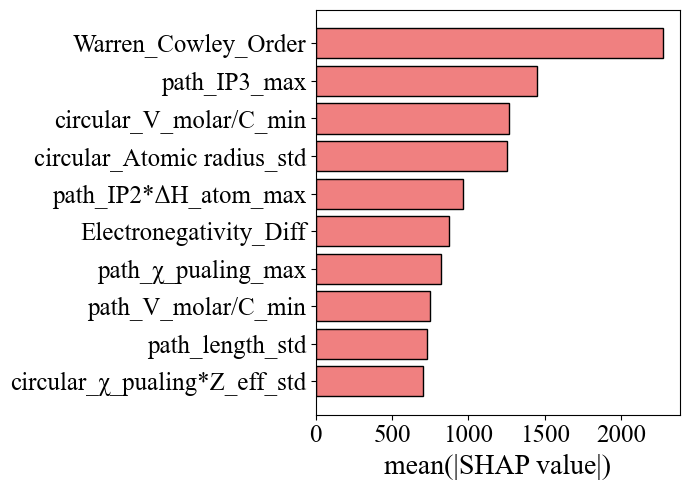

In [45]:
top_features = np.array(FEATURES)[indices]
top_means = overall_importance[indices]
top_stds = importance_std[indices]

top_features = top_features[::-1]
top_means = top_means[::-1]
top_stds = top_stds[::-1]

plt.figure(figsize=(7,5))

plt.barh(
    top_features,
    top_means,
    #xerr=top_stds,
    capsize=5,
    color='lightcoral',
    edgecolor='black'
)

plt.xlabel('mean(|SHAP value|)', fontsize=20)

plt.xticks(fontsize=18, fontfamily='Times New Roman')
plt.yticks(fontsize=18, fontfamily='Times New Roman')

plt.tight_layout()

plt.savefig("SHAP_importance_first_10.png", dpi=400, bbox_inches='tight')
plt.show()

## SHAP_interaction_heatmap_with_diagonal

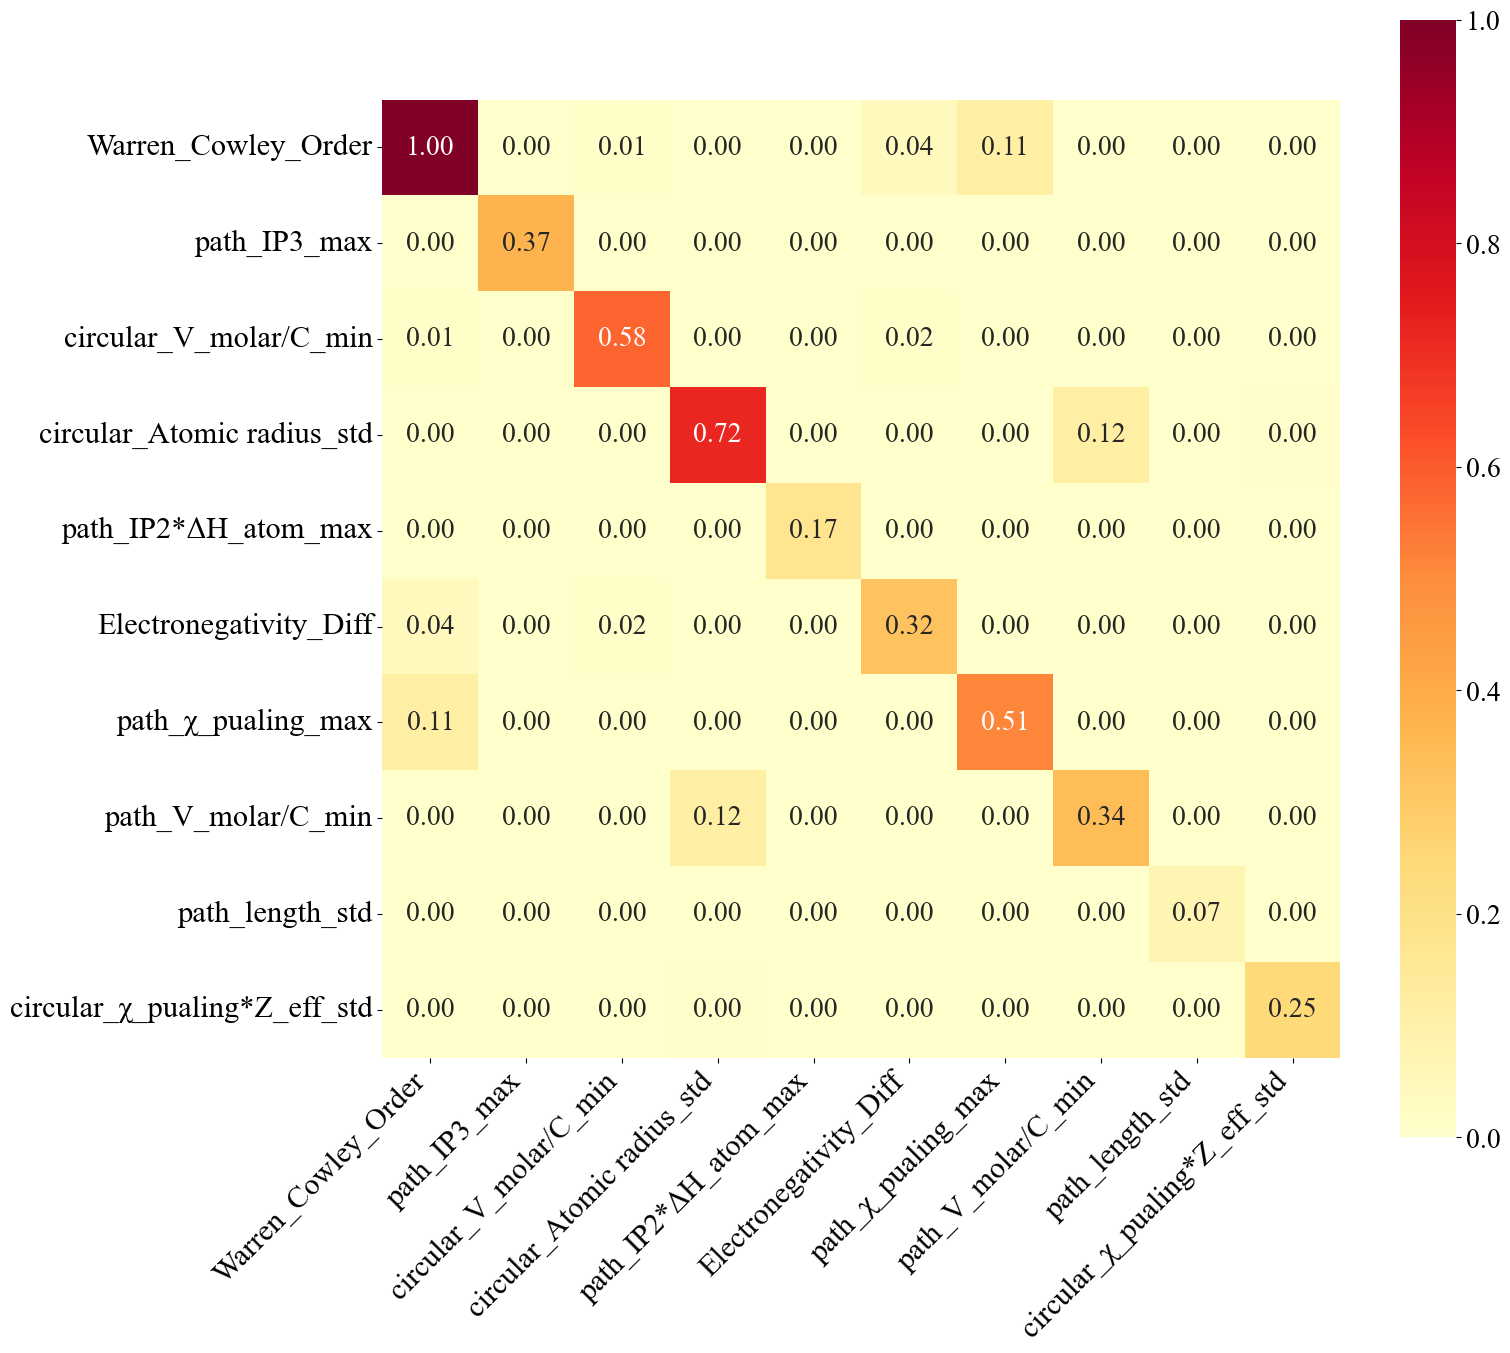

In [46]:
xgb_model_first = models[0].named_steps['xgb']
X_train_transformed = Pipeline(models[0].steps[:1]).transform(df_train_allsites[FEATURES])

explainer_inter = shap.TreeExplainer(xgb_model_first)
interaction_values = explainer_inter.shap_interaction_values(X_train_transformed)
mean_interaction = np.mean(np.abs(interaction_values), axis=0)

top_n = 10
top_idx = np.argsort(overall_importance)[::-1][:top_n]

interaction_top = mean_interaction[np.ix_(top_idx, top_idx)]
feature_names_top = np.array(FEATURES)[top_idx]

interaction_top = interaction_top / np.max(interaction_top)

plt.figure(figsize=(16, 14))
ax = sns.heatmap(
    interaction_top,
    xticklabels=feature_names_top,
    yticklabels=feature_names_top,
    cmap="YlOrRd",
    annot_kws={"size": 20},
    annot=True,
    fmt=".2f",
    square=True,
    #cbar_kws={"label": "Normalized interaction strength"}
)

plt.xticks(rotation=45, ha="right", fontsize=22)
plt.yticks(rotation=0, fontsize=22)

#ax.set_title("SHAP Interaction Heatmap", fontsize=20)

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=20)
plt.savefig("SHAP_interaction_heatmap_with_diagonal.pdf", dpi=600, bbox_inches='tight')
plt.savefig("SHAP_interaction_heatmap_with_diagonal.png", dpi=600, bbox_inches='tight')

plt.tight_layout()
plt.show()

## Partial Dependence Plot

<Figure size 1000x600 with 0 Axes>

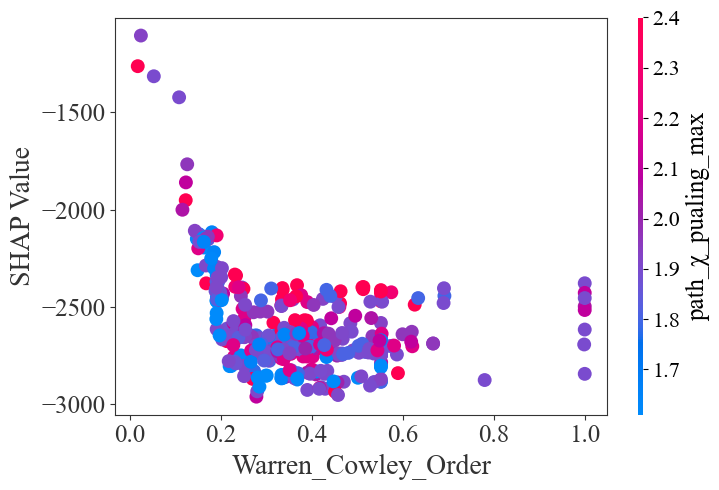

In [51]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from matplotlib.collections import PathCollection

def plot_shap_dependence_all(
    feature_name, 
    X_train_filtered, 
    models, 
    FEATURES, 
    pipeline=True, 
    interaction_feature=None,
    x_lim=None, 
    y_lim=None, 
    title_fontsize=22, 
    label_fontsize=20, 
    tick_fontsize=18,
    point_size=20
):

    if feature_name not in FEATURES:
        print(f"Error: Feature '{feature_name}' not found")
        return
    if interaction_feature and interaction_feature not in FEATURES:
        print(f"Error: Interaction feature '{interaction_feature}' not found")
        return

    samples_df = X_train_filtered[FEATURES]
    if samples_df.empty:
        print("Error: X_train_filtered is empty")
        return

    shap_values_list = []
    for model in models:
        xgb_model = model.named_steps['xgb'] if pipeline else model
        explainer = shap.TreeExplainer(xgb_model)
        shap_values = explainer.shap_values(samples_df)
        shap_values_list.append(shap_values)

    shap_values_array = np.mean(shap_values_list, axis=0)

    plt.figure(figsize=(10, 6))
    shap.dependence_plot(
        feature_name,
        shap_values_array,
        samples_df,
        feature_names=FEATURES,
        interaction_index=interaction_feature,
        show=False
    )

    ax = plt.gca()

    for child in ax.get_children():
        if isinstance(child, PathCollection):
            child.set_sizes([point_size])

    if x_lim is not None:
        ax.set_xlim(x_lim)
    if y_lim is not None:
        ax.set_ylim(y_lim)

    ax.set_xlabel(feature_name, fontsize=label_fontsize)
    ax.set_ylabel("SHAP Value", fontsize=label_fontsize)
    ax.tick_params(axis='both', which='major', labelsize=tick_fontsize)

    ax.spines['top'].set_visible(True)
    ax.spines['right'].set_visible(True)

    cbar = None
    fig = plt.gcf()
    for cb in fig.get_axes():
        if isinstance(cb, plt.Axes) and cb.get_label().startswith('<colorbar'):
            cbar = cb
            break

    if cbar is not None:
        try:
            label = interaction_feature
            cbar.set_ylabel(label, fontsize=18)
            cbar.tick_params(axis='y', labelsize=16)
            for text in cbar.get_yticklabels():
                text.set_fontsize(16)
        except Exception as e:
            print(f"Error modifying color bar: {e}")

    plt.tight_layout()
    plt.show()

plot_shap_dependence_all(
    feature_name='Warren_Cowley_Order',
    X_train_filtered=df_train_allsites,
    models=models,
    FEATURES=FEATURES,
    pipeline=True,
    interaction_feature='path_χ_pualing_max',
    point_size=100
)


# Plot training set learning curve(621 samples + chemical descripors)

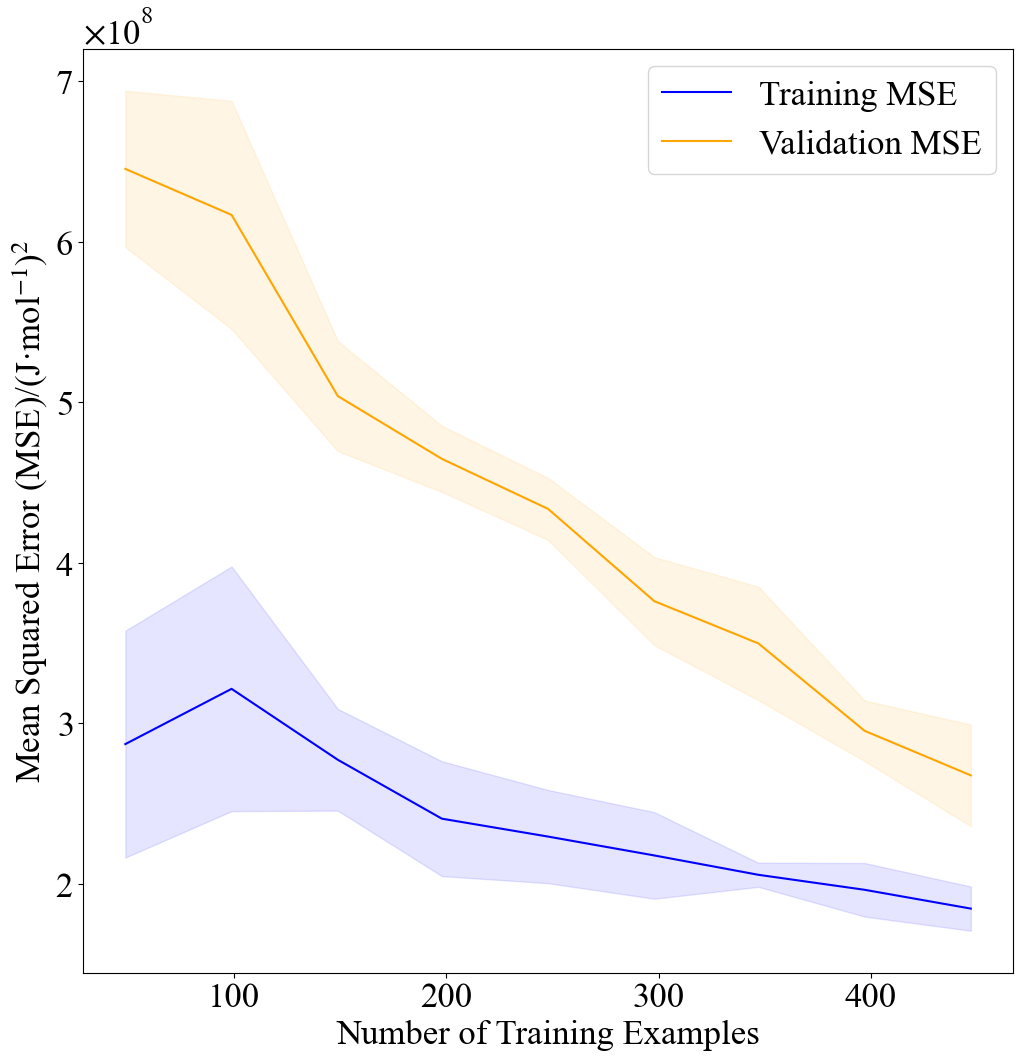

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.metrics import mean_squared_error

plt.rcParams['font.family'] = 'Times New Roman'

N_ensemble = 10
train_sizes = np.linspace(0.1, 0.9, 9)
train_sizes_absolute = (train_sizes * len(df_train_allsites)).astype(int)

X = df_train_allsites[FEATURES]
y = df_train_allsites[TARGET]

train_scores = np.zeros((len(train_sizes), N_ensemble))
test_scores = np.zeros((len(train_sizes), N_ensemble))

for i, (train_size_float, train_size_int) in enumerate(zip(train_sizes, train_sizes_absolute)):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, train_size=train_size_float, test_size=1.0-train_size_float, random_state=42
    )
    Xs = []
    for j in range(N_ensemble):
        X_sample = resample(
            pd.concat([X_train, y_train], axis=1),
            replace=True,
            n_samples=train_size_int,  
            random_state=j
        )
        Xs.append(X_sample)
    for j, X_sample in enumerate(Xs):
        model = xgb_model(xgb_hyperparams, X_sample, FEATURES, TARGET)
        y_train_pred = model.predict(X_train)
        train_scores[i, j] = mean_squared_error(y_train, y_train_pred)
        y_test_pred = model.predict(X_test)
        test_scores[i, j] = mean_squared_error(y_test, y_test_pred)

train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)
test_scores_std = np.std(test_scores, axis=1)

plt.figure(figsize=(12, 12))
plt.plot(train_sizes_absolute, train_scores_mean, label="Training MSE", color="blue")
plt.plot(train_sizes_absolute, test_scores_mean, label="Validation MSE", color="orange")
plt.fill_between(train_sizes_absolute,
                 train_scores_mean - train_scores_std,
                 train_scores_mean + train_scores_std,
                 alpha=0.1, color="blue")
plt.fill_between(train_sizes_absolute,
                 test_scores_mean - test_scores_std,
                 test_scores_mean + test_scores_std,
                 alpha=0.1, color="orange")
plt.xlabel("Number of Training Examples", fontfamily='Times New Roman', fontsize=25)
plt.ylabel("Mean Squared Error (MSE)/(J·mol$^{-1}$)$^{2}$", fontfamily='Times New Roman', fontsize=25)
plt.legend(loc="best", prop={'family': 'Times New Roman', 'size': 25})
ax = plt.gca()
formatter = ticker.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
ax.yaxis.set_major_formatter(formatter)
ax.yaxis.get_offset_text().set_visible(True)
ax.yaxis.set_offset_position('left')
ax.yaxis.get_offset_text().set_fontfamily('Times New Roman')
ax.yaxis.get_offset_text().set_size(25)
ax.yaxis.get_offset_text().set_text(r'$\times 10^{8}$')
ax.tick_params(axis='both', which='major', labelsize=25, labelfontfamily='Times New Roman')
plt.grid(False)


# Predict the Gibbs free energy of formation for intermetallic phases

In [52]:
df_features = pd.read_csv("D:/code&data availability/OOD validation/features of binary IMCs with enthalpy(C+new_PLMF+MP+NN24).csv",encoding='gb2312')
df_features

,Formula,MP_ID,SIPFENN_Krajewski2020_NN24,Formation Energy per Atom (eV/atom),Energy per Atom (eV/atom),Total Magnetic Moment (μ_B),Electronegativity_Diff,Fraction_A,Fraction_B,Atomic_Radius_Diff,...,T_E_Boiling point,T_E_bond_Boiling point,T_E_χ_MB,T_E_bond_χ_MB,T_E_r_s,T_E_bond_r_s,T_E_r_p,T_E_bond_r_p,T_E_r_d,T_E_bond_r_d
0,Ni3Zn,mp-971758,-0.121654,-0.113473,-4.763512,1.484181e+00,0.26,0.750000,0.250000,2,...,1.310000e-14,1.080000e-14,1.490000e-14,5.210000e-14,7.700000e-12,1.490000e-11,8.500000e-17,1.040000e-15,1.190000e-15,1.490000e-16
1,NiZn,mp-429,-0.261455,-0.254971,-3.774911,6.000000e-07,0.26,0.500000,0.500000,2,...,1.430000e-14,1.180000e-14,1.620000e-14,5.670000e-14,8.390000e-12,1.630000e-11,9.260000e-17,1.130000e-15,1.300000e-15,1.620000e-16
2,Pd2Zn,mp-1103252,-0.363461,-0.317801,-4.517648,2.900000e-06,0.55,0.750000,0.250000,17,...,7.750623e+01,1.289669e+01,3.185624e+01,1.114968e+02,1.808431e+04,3.274821e+04,9.937808e-01,4.141311e+00,4.937717e+00,3.583827e+00
3,Pd3Zn,mp-1187913,-0.318790,-0.462197,-4.335367,0.000000e+00,0.55,0.666667,0.333333,17,...,1.820000e-13,3.030000e-14,7.480000e-14,2.620000e-13,4.250000e-11,7.690000e-11,2.330000e-15,9.730000e-15,1.160000e-14,8.420000e-15
4,PdZn,mp-1652,-0.374483,-0.576281,-3.796093,0.000000e+00,0.55,0.500000,0.500000,17,...,2.590000e-14,4.310000e-15,1.070000e-14,3.730000e-14,6.050000e-12,1.100000e-11,3.320000e-16,1.390000e-15,1.650000e-15,1.200000e-15
5,PdZn2,mp-1215714,-0.519975,-0.437537,-3.003993,0.000000e+00,0.55,0.333333,0.666667,17,...,2.190115e+02,3.644253e+01,9.001705e+01,3.150597e+02,5.110133e+04,9.253753e+04,2.808154e+00,1.170222e+01,1.395264e+01,1.012692e+01
6,Pt3Zn,mp-30856,-0.250322,-0.312520,-5.180806,3.350000e-05,0.63,0.750000,0.250000,14,...,1.160000e-13,1.040000e-14,1.620000e-14,6.480000e-14,1.090000e-11,2.360000e-11,9.360000e-15,3.400000e-15,3.240000e-15,2.720000e-15
7,PtZn,mp-894,-0.394417,-0.565284,-4.230722,0.000000e+00,0.63,0.500000,0.500000,14,...,7.970000e-14,7.110000e-15,1.110000e-14,4.440000e-14,7.490000e-12,1.620000e-11,6.410000e-15,2.330000e-15,2.220000e-15,1.860000e-15
8,RuZn3,mp-1380,-0.098607,-0.151520,-3.414928,4.000000e-07,0.55,0.250000,0.750000,24,...,1.333696e+02,4.140877e+01,1.074262e+02,4.028483e+02,5.141203e+04,8.709579e+04,4.933884e+00,8.728379e+00,1.074262e+01,7.385551e+00


In [53]:
df_predictions_300K=predict_G_ensemble_dataset(models=models, FEATURES=FEATURES, df_features=df_features, temperature=300)
print(df_predictions_300K)

[{'name': 'mp-971758', 'predicted_G_molar_300_mean': -18421.938, 'predicted_G_molar_300_std': 3443.8057}, {'name': 'mp-429', 'predicted_G_molar_300_mean': -24686.758, 'predicted_G_molar_300_std': 4551.7812}, {'name': 'mp-1103252', 'predicted_G_molar_300_mean': -36813.137, 'predicted_G_molar_300_std': 11453.995}, {'name': 'mp-1187913', 'predicted_G_molar_300_mean': -34462.42, 'predicted_G_molar_300_std': 8352.47}, {'name': 'mp-1652', 'predicted_G_molar_300_mean': -39224.15, 'predicted_G_molar_300_std': 8545.557}, {'name': 'mp-1215714', 'predicted_G_molar_300_mean': -35640.246, 'predicted_G_molar_300_std': 12934.314}, {'name': 'mp-30856', 'predicted_G_molar_300_mean': -27110.215, 'predicted_G_molar_300_std': 8075.893}, {'name': 'mp-894', 'predicted_G_molar_300_mean': -38212.195, 'predicted_G_molar_300_std': 8427.757}, {'name': 'mp-1380', 'predicted_G_molar_300_mean': -25714.742, 'predicted_G_molar_300_std': 4927.377}]
